# AI401 — Intelligent Multi-Agent and Expert Systems
# Experiment 3: Agent Architectures — The BDI Deliberation Cycle

**SVNIT, Surat — Department of Artificial Intelligence — Semester VII**

## Aim
Implement a Belief–Desire–Intention (BDI) agent that revises beliefs in a dynamic environment, deliberates over competing desires, commits to an intention, executes a plan, and measures how commitment affects performance as the world changes faster.

# 1. Theory

A BDI architecture separates:

- **Beliefs:** what the agent currently takes to be true, revised from percepts.
- **Desires:** states of affairs the agent would like to achieve; options rather than commitments.
- **Intentions:** desires to which the agent has committed and which constrain future action.

The control functions are:

`brf(B,p) → options(B,I) → filter(B,D,I) → plan(B,I)`

The assignment emphasizes time pressure: the world changes while the agent deliberates. Single-minded commitment retains an intention while it remains achievable; it drops the intention when it becomes unachievable. γ is the number of actions between scheduled reconsiderations. γ=1 is cautious; γ larger than relevant plan lengths is bold.

# 2. Assignment Algorithm

1. Perceive and revise beliefs.
2. If intention is null or the plan is empty, generate options, filter an intention, and plan.
3. Execute the first action; the world advances during the action.
4. If the intention is achieved, drop it.
5. Otherwise apply the single-minded reconsideration rule.
6. Repeat for the required number of agent time steps.

Scheduled reconsideration costs **one agent time step** and advances the world, as required by the assignment.

In [1]:
import math, time
from dataclasses import dataclass
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("Environment ready")

Environment ready


# 3. Explicit Simulation Configuration

Documented implementation assumptions for unspecified stochastic parameters:
- Grid = 15×15.
- Hole appearance probability = 0.08 per empty cell per world tick.
- Lifetime = uniformly random integer 3–10 ticks.
- Start = centre `(7,7)`.
- A hole is filled when the agent enters its cell while it is still active.
- World speed = world ticks per agent action.
- Effectiveness = holes filled / holes appeared.

In [2]:
GRID_SIZE=15
HOLE_APPEAR_PROB=0.08
HOLE_LIFETIME_MIN=3
HOLE_LIFETIME_MAX=10
START=(7,7)
AGENT_STEPS=600
SEEDS_PER_SETTING=25
GAMMAS=[1,2,4,8,"bold"]
WORLD_SPEEDS=[1,2,4,8]
BOLD_GAMMA=math.inf
print(GRID_SIZE, AGENT_STEPS, SEEDS_PER_SETTING, GAMMAS, WORLD_SPEEDS)

15 600 25 [1, 2, 4, 8, 'bold'] [1, 2, 4, 8]


# 4. Tileworld Environment

In [3]:
class Tileworld:
    def __init__(self,seed,size=GRID_SIZE,appearance_prob=HOLE_APPEAR_PROB,lifetime_min=HOLE_LIFETIME_MIN,lifetime_max=HOLE_LIFETIME_MAX):
        self.rng=np.random.default_rng(seed); self.size=size; self.appearance_prob=appearance_prob
        self.lifetime_min=lifetime_min; self.lifetime_max=lifetime_max; self.holes={}; self.tick=0; self.holes_appeared=0; self.holes_filled=0
    def step(self):
        self.tick+=1
        for cell in list(self.holes):
            self.holes[cell]-=1
            if self.holes[cell]<=0: del self.holes[cell]
        total=self.size*self.size; available=total-len(self.holes); k=int(self.rng.binomial(available,self.appearance_prob))
        if k:
            candidates=np.array([i for i in range(total) if (i//self.size,i%self.size) not in self.holes],dtype=np.int16)
            for idx in self.rng.choice(candidates,k,replace=False):
                cell=(int(idx)//self.size,int(idx)%self.size); self.holes[cell]=int(self.rng.integers(self.lifetime_min,self.lifetime_max+1))
            self.holes_appeared+=k
    def advance(self,ticks):
        for _ in range(int(ticks)): self.step()
    def fill(self,cell):
        if cell in self.holes: del self.holes[cell]; self.holes_filled+=1; return True
        return False
    def hole_cells(self): return set(self.holes)
    def snapshot(self): return {"tick":self.tick,"holes":len(self.holes),"appeared":self.holes_appeared,"filled":self.holes_filled}

# 5. Beliefs — `brf(B,p)`

In [4]:
@dataclass
class Beliefs:
    position:tuple
    holes:frozenset
    world_tick:int

def perceive(world,position):
    return {"position":position,"holes":frozenset(world.hole_cells()),"world_tick":world.tick}

def brf(previous_beliefs,percept):
    return Beliefs(percept["position"],percept["holes"],percept["world_tick"])

# 6. BFS Means–Ends Planner

The assignment defines the plan as the shortest path to the selected hole. BFS is used on the unweighted 4-neighbour grid.

In [5]:
MOVES=[(-1,0,"UP"),(1,0,"DOWN"),(0,-1,"LEFT"),(0,1,"RIGHT")]
def apply_action(pos,action):
    r,c=pos
    for dr,dc,name in MOVES:
        if name==action:return (r+dr,c+dc)
    raise ValueError(action)
def bfs_shortest_path(start,goal,size=GRID_SIZE):
    if start==goal:return []
    q=deque([start]); parent={start:None}; act={}
    while q:
        cur=q.popleft()
        for dr,dc,a in MOVES:
            nxt=(cur[0]+dr,cur[1]+dc)
            if not(0<=nxt[0]<size and 0<=nxt[1]<size) or nxt in parent:continue
            parent[nxt]=cur; act[nxt]=a
            if nxt==goal:
                path=[]; x=goal
                while parent[x] is not None:path.append(act[x]); x=parent[x]
                return path[::-1]
            q.append(nxt)
    return None
def shortest_path(start,goal,size=GRID_SIZE):
    # The Tileworld has no obstacles, so a Manhattan path is a shortest path.
    # BFS above is retained as the explicit search implementation and is tested below.
    if start==goal:return []
    path=[]; r,c=start; gr,gc=goal
    while r<gr:path.append("DOWN"); r+=1
    while r>gr:path.append("UP"); r-=1
    while c<gc:path.append("RIGHT"); c+=1
    while c>gc:path.append("LEFT"); c-=1
    return path
print("BFS shortest-path length:",len(bfs_shortest_path((0,0),(3,4))))
print("Simulation planner shortest-path length:",len(shortest_path((0,0),(3,4))))

BFS shortest-path length: 7
Simulation planner shortest-path length: 7


# 7. Desires and Filter

Every active hole is a desire. The base filter uses nearest-hole-first ordering and retains an achievable current intention under single-minded commitment.

In [6]:
def manhattan(a,b): return abs(a[0]-b[0])+abs(a[1]-b[1])
def options(beliefs,intention=None): return sorted(beliefs.holes,key=lambda h:(manhattan(beliefs.position,h),h))
def is_achievable(beliefs,intention): return intention is not None and intention in beliefs.holes
def filter_intention(beliefs,desires,current_intention=None):
    return desires[0] if desires else None

# 8. Complete BDI Agent

The implementation counts exactly 600 **agent time steps**, including scheduled deliberation steps. Initial option selection is performed before action execution; scheduled reconsideration consumes one time step and advances the world.

In [7]:
class BDIAgent:
    def __init__(self,start,gamma,world_speed=1,size=GRID_SIZE):
        self.position=start; self.gamma=gamma; self.world_speed=world_speed; self.size=size
        self.beliefs=None; self.intention=None; self.plan=[]; self.since_reconsider=0
        self.steps=0; self.deliberations=0; self.commits=0; self.achievements=0; self.drops=0; self.switches=0; self.no_action=0
        self.trace=[]
    def log(self,event,world,**kw):
        self.trace.append({"agent_step":self.steps,"world_tick":world.tick,"event":event,"position":self.position,"intention":self.intention,**kw})
    def revise(self,world): self.beliefs=brf(self.beliefs,perceive(world,self.position))
    def choose(self,world,reason="selection"):
        self.revise(world); desires=options(self.beliefs,self.intention); old=self.intention
        preferred=filter_intention(self.beliefs,desires,self.intention)
        if preferred!=old:
            if old is None and preferred is not None:
                self.commits+=1; self.log("COMMIT",world,reason=reason,new_intention=preferred)
            elif old is not None and preferred is None:
                self.drops+=1; self.log("DROP",world,reason=reason,dropped_intention=old)
            elif old is not None and preferred is not None:
                self.switches+=1; self.log("SWITCH",world,reason=reason,old_intention=old,new_intention=preferred)
        self.intention=preferred
        self.plan=shortest_path(self.position,preferred,self.size) if preferred is not None else []
    def scheduled_reconsider(self,world):
        if self.gamma==math.inf or self.since_reconsider<self.gamma:return False
        self.since_reconsider=0; world.advance(self.world_speed); self.steps+=1; self.deliberations+=1
        self.log("DELIBERATE",world,reason="scheduled_reconsideration")
        self.revise(world)
        if self.intention is not None and not is_achievable(self.beliefs,self.intention):
            old=self.intention; self.intention=None; self.plan=[]; self.drops+=1
            self.log("DROP",world,reason="intention_unachievable",dropped_intention=old)
            self.choose(world,"after_drop"); return True
        desires=options(self.beliefs,self.intention); preferred=filter_intention(self.beliefs,desires,self.intention)
        if preferred!=self.intention:
            old=self.intention; self.intention=preferred
            self.plan=shortest_path(self.position,preferred,self.size) if preferred is not None else []
            if preferred is None:self.drops+=1; self.log("DROP",world,reason="no_desire",dropped_intention=old)
            else:self.switches+=1; self.log("SWITCH",world,reason="preferred_option_changed",old_intention=old,new_intention=preferred)
        else:self.log("RETAIN",world,reason="preferred_option_unchanged")
        return True
    def run(self,world,agent_steps=600):
        self.choose(world,"initial")
        while self.steps<agent_steps:
            if self.intention is None or not self.plan:self.choose(world,"no_intention_or_empty_plan")
            if self.steps>=agent_steps:break
            if self.intention is None or not self.plan:
                world.advance(self.world_speed); self.steps+=1; self.no_action+=1; self.log("NO_ACTION",world,reason="no_achievable_desire"); continue
            action=self.plan.pop(0); self.position=apply_action(self.position,action); world.advance(self.world_speed); self.steps+=1; self.since_reconsider+=1
            filled=world.fill(self.position)
            if filled:
                self.achievements+=1; self.log("ACHIEVE",world,action=action,filled=True)
                if self.intention==self.position:
                    old=self.intention; self.intention=None; self.plan=[]; self.since_reconsider=0; self.drops+=1
                    self.log("DROP",world,reason="intention_achieved",dropped_intention=old)
            else:
                pass
            self.revise(world)
            if self.intention is not None and self.steps<agent_steps:self.scheduled_reconsider(world)
        eff=world.holes_filled/world.holes_appeared if world.holes_appeared else 0.0
        return {"effectiveness":eff,"holes_filled":world.holes_filled,"holes_appeared":world.holes_appeared,"steps":self.steps,"deliberations":self.deliberations,"commits":self.commits,"achievements":self.achievements,"drops":self.drops,"switches":self.switches,"no_action_steps":self.no_action,"event_trace":pd.DataFrame(self.trace)}

# 9. Demonstration Run and Event Trace

In [8]:
demo_world=Tileworld(42); demo_agent=BDIAgent(START,1,2); demo=demo_agent.run(demo_world,80)
print({k:v for k,v in demo.items() if k!="event_trace"}); display(demo["event_trace"].head(50))

{'effectiveness': 0.01566324033284386, 'holes_filled': 32, 'holes_appeared': 2043, 'steps': 80, 'deliberations': 19, 'commits': 42, 'achievements': 32, 'drops': 42, 'switches': 2, 'no_action_steps': 12}


,agent_step,world_tick,event,position,intention,reason,new_intention,old_intention,dropped_intention,action,filled
0,1,2,NO_ACTION,"(7, 7)",None,no_achievable_desire,NaN,NaN,NaN,NaN,NaN
1,1,2,COMMIT,"(7, 7)",None,no_intention_or_empty_plan,"(7, 7)",NaN,NaN,NaN,NaN
2,2,4,NO_ACTION,"(7, 7)","(7, 7)",no_achievable_desire,NaN,NaN,NaN,NaN,NaN
3,3,6,NO_ACTION,"(7, 7)","(7, 7)",no_achievable_desire,NaN,NaN,NaN,NaN,NaN
4,4,8,NO_ACTION,"(7, 7)","(7, 7)",no_achievable_desire,NaN,NaN,NaN,NaN,NaN
5,5,10,NO_ACTION,"(7, 7)","(7, 7)",no_achievable_desire,NaN,NaN,NaN,NaN,NaN
6,5,10,SWITCH,"(7, 7)","(7, 7)",no_intention_or_empty_plan,"(7, 6)","(7, 7)",NaN,NaN,NaN
7,7,14,DELIBERATE,"(7, 6)","(7, 6)",scheduled_reconsideration,NaN,NaN,NaN,NaN,NaN
8,7,14,DROP,"(7, 6)",None,intention_unachievable,NaN,NaN,"(7, 6)",NaN,NaN
9,7,14,COMMIT,"(7, 6)",None,after_drop,"(7, 5)",NaN,NaN,NaN,NaN


,Count
event,
COMMIT,42
DROP,42
ACHIEVE,32
DELIBERATE,19
NO_ACTION,12
RETAIN,7
SWITCH,2


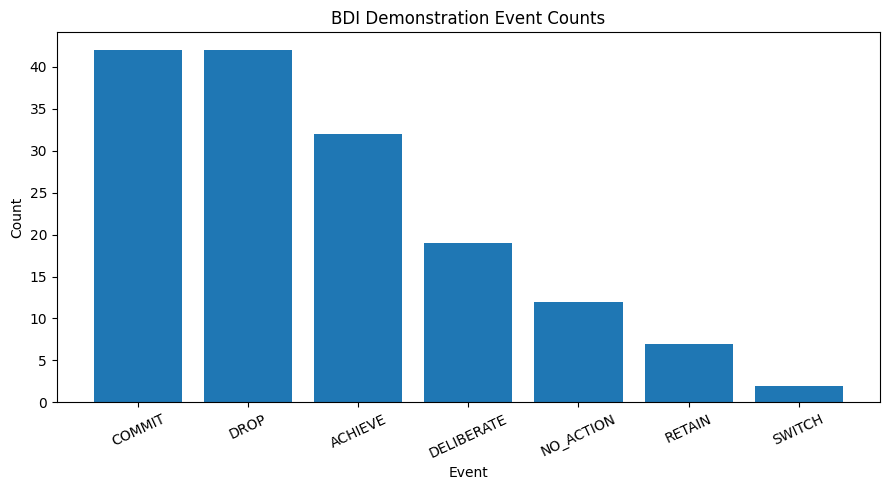

In [9]:
events=demo["event_trace"]["event"].value_counts(); display(events.to_frame("Count"))
fig,ax=plt.subplots(figsize=(9,5)); ax.bar(events.index,events.values); ax.set_title("BDI Demonstration Event Counts"); ax.set_xlabel("Event"); ax.set_ylabel("Count"); ax.tick_params(axis="x",rotation=25); plt.tight_layout(); plt.show()

# 10. Exercise 1 — Boldness Against Dynamism

Exactly 25 seeds are averaged for every γ/speed pair, with 600 agent time steps per simulation. This gives 500 simulations.

In [10]:
def run_setting(gamma,world_speed,seeds,agent_steps=AGENT_STEPS):
    rows=[]
    for seed in seeds:
        w=Tileworld(seed); a=BDIAgent(START,gamma,world_speed); r=a.run(w,agent_steps)
        rows.append({"gamma":gamma,"world_speed":world_speed,"seed":seed,"effectiveness":r["effectiveness"],"holes_filled":r["holes_filled"],"holes_appeared":r["holes_appeared"],"deliberations":r["deliberations"],"switches":r["switches"],"drops":r["drops"],"agent_steps":r["steps"]})
    return rows
seeds=list(range(1,SEEDS_PER_SETTING+1)); rows=[]; t0=time.perf_counter()
for speed in WORLD_SPEEDS:
    for label in GAMMAS: rows += run_setting(math.inf if label=="bold" else label,speed,seeds)
experiment_df=pd.DataFrame(rows); experiment_df["gamma_label"]=experiment_df["gamma"].map(lambda x:"bold" if math.isinf(x) else int(x))
print("Simulations:",len(experiment_df),"Elapsed:",round(time.perf_counter()-t0,2),"seconds")
print("All runs exactly 600 steps:",experiment_df["agent_steps"].eq(600).all())

Simulations: 500 Elapsed: 109.8 seconds
All runs exactly 600 steps: True


# 11. Exercise 1 — Results Table

In [11]:
summary=(experiment_df.groupby(["world_speed","gamma_label"]).agg(mean_effectiveness=("effectiveness","mean"),std_effectiveness=("effectiveness","std"),mean_filled=("holes_filled","mean"),mean_appeared=("holes_appeared","mean"),mean_deliberations=("deliberations","mean"),mean_switches=("switches","mean"),mean_drops=("drops","mean")).reset_index())
display(summary.style.format({c:"{:.4f}" for c in ["mean_effectiveness","std_effectiveness"]}).format({c:"{:.2f}" for c in ["mean_filled","mean_appeared","mean_deliberations","mean_switches","mean_drops"]}))

best=(summary.loc[summary.groupby("world_speed")["mean_effectiveness"].idxmax()].sort_values("world_speed")); print("Best gamma at each speed:"); display(best[["world_speed","gamma_label","mean_effectiveness"]].style.format({"mean_effectiveness":"{:.4f}"}))

,world_speed,gamma_label,mean_effectiveness,std_effectiveness,mean_filled,mean_appeared,mean_deliberations,mean_switches,mean_drops
0,1,1,0.032255,0.002651,243.96,7563.48,138.96,34.88,286.84
1,1,2,0.043661,0.002605,330.32,7567.04,50.16,35.00,347.60
2,1,4,0.048772,0.002394,369.32,7572.28,9.16,62.24,358.76
3,1,8,0.049554,0.001690,375.20,7572.64,0.08,64.32,359.12
4,1,bold,0.049554,0.001691,375.48,7578.24,0.00,64.64,359.32
5,2,1,0.014173,0.000991,213.04,15031.48,153.80,45.88,291.24
6,2,2,0.018185,0.001362,273.68,15053.12,75.64,72.92,308.24
7,2,4,0.021615,0.001047,325.60,15063.64,16.68,122.04,313.40
8,2,8,0.022771,0.000804,343.20,15072.44,0.64,129.08,318.36
9,2,bold,0.022831,0.000735,344.00,15067.20,0.00,130.24,318.88


Best gamma at each speed:


,world_speed,gamma_label,mean_effectiveness
4,1,bold,0.0496
9,2,bold,0.0228
14,4,bold,0.0089
19,8,bold,0.0034


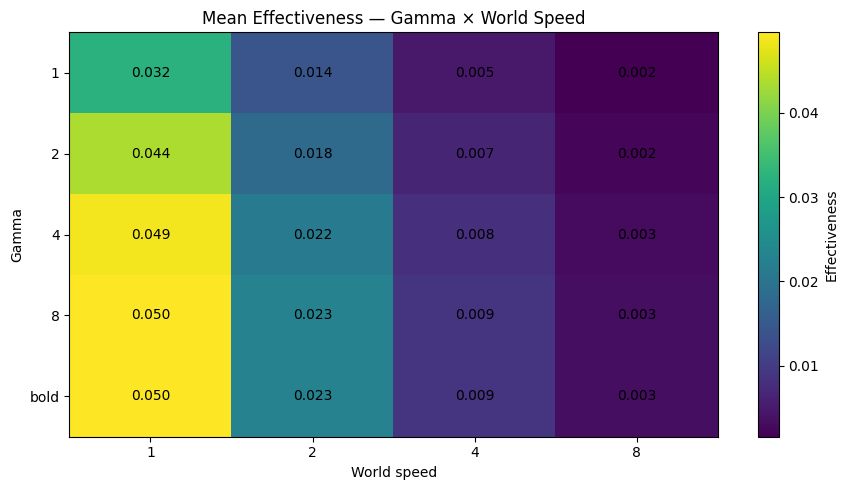

In [12]:
order=[1,2,4,8,"bold"]; pivot=summary.pivot(index="gamma_label",columns="world_speed",values="mean_effectiveness").reindex(order)
fig,ax=plt.subplots(figsize=(9,5)); im=ax.imshow(pivot.values,aspect="auto",interpolation="nearest"); ax.set_title("Mean Effectiveness — Gamma × World Speed"); ax.set_xlabel("World speed"); ax.set_ylabel("Gamma"); ax.set_xticks(range(4)); ax.set_xticklabels(WORLD_SPEEDS); ax.set_yticks(range(5)); ax.set_yticklabels(order)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]): ax.text(j,i,f"{pivot.iloc[i,j]:.3f}",ha="center",va="center")
plt.colorbar(im,ax=ax,label="Effectiveness"); plt.tight_layout(); plt.show()

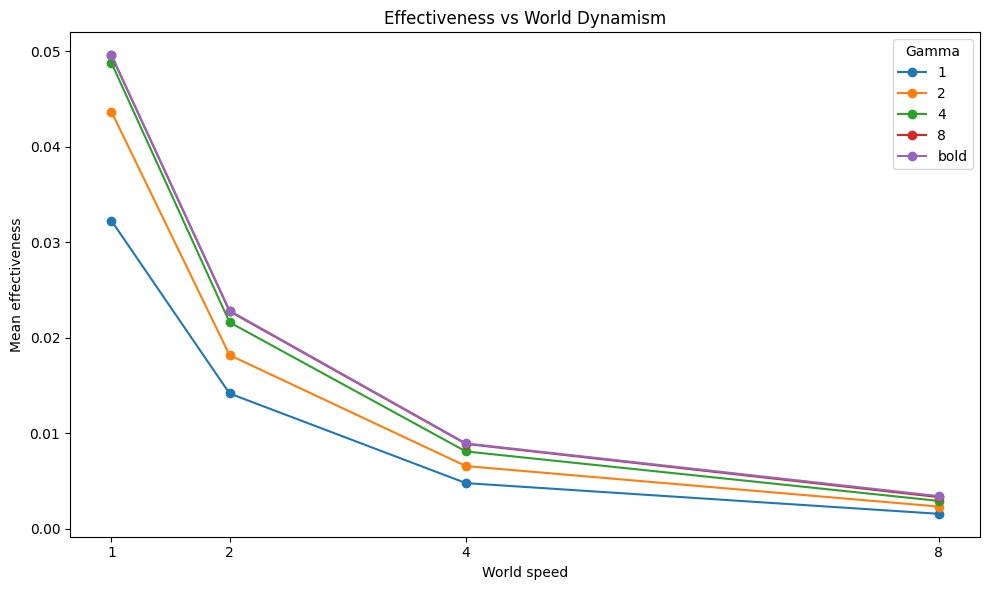

In [13]:
fig,ax=plt.subplots(figsize=(10,6))
for g in order:
    sub=summary[summary.gamma_label==g].sort_values("world_speed"); ax.plot(sub.world_speed,sub.mean_effectiveness,marker="o",label=str(g))
ax.set_title("Effectiveness vs World Dynamism"); ax.set_xlabel("World speed"); ax.set_ylabel("Mean effectiveness"); ax.set_xticks(WORLD_SPEEDS); ax.legend(title="Gamma"); plt.tight_layout(); plt.show()

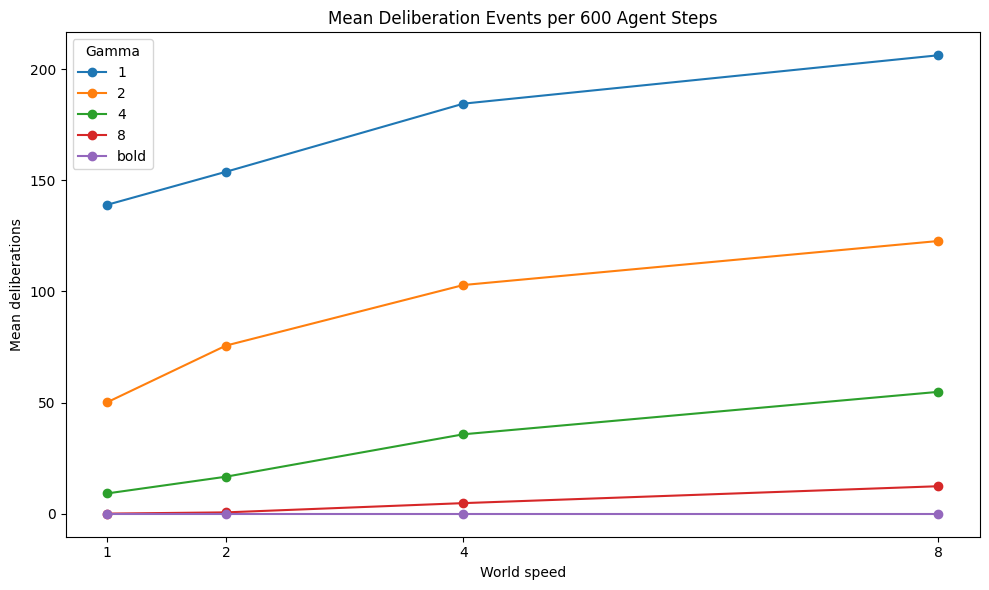

In [14]:
cost=experiment_df.groupby(["world_speed","gamma_label"]).deliberations.mean().reset_index(); fig,ax=plt.subplots(figsize=(10,6))
for g in order:
    sub=cost[cost.gamma_label==g].sort_values("world_speed"); ax.plot(sub.world_speed,sub.deliberations,marker="o",label=str(g))
ax.set_title("Mean Deliberation Events per 600 Agent Steps"); ax.set_xlabel("World speed"); ax.set_ylabel("Mean deliberations"); ax.set_xticks(WORLD_SPEEDS); ax.legend(title="Gamma"); plt.tight_layout(); plt.show()

## Exercise 1 interpretation

- γ=1 is highly responsive but spends many time steps reconsidering.
- Bold avoids scheduled reconsideration and is attractive in slowly changing worlds, but stale intentions can become costly in dynamic worlds.
- Intermediate γ balances execution stability against adaptation.
- As world speed increases, environmental changes occur more often between decisions, so the useful optimum should generally move toward smaller γ.
- The **actual numerical optimum for this documented stochastic configuration is the value in the Best γ table above**, not a value asserted in advance.

# 12. Exercise 2 — Resource-Bounded Filter

Battery capacity is 40. Each move costs 1. A charger restores the battery. The `fill-hole` option is feasible only when:

`distance(current, hole) + distance(hole, charger) <= battery`.

Otherwise the filter selects `recharge`. The planner remains a means–ends planner for the selected intention.

In [15]:
BATTERY_CAPACITY=40; BATTERY_COST=1; CHARGER=(0,0)
@dataclass
class ResourceBeliefs:
    position:tuple; holes:frozenset; world_tick:int; battery:int; charger:tuple

def resource_options(b):
    vals=[(h,manhattan(b.position,h)+manhattan(h,b.charger)) for h in b.holes]
    return sorted([(h,req) for h,req in vals if req<=b.battery],key=lambda x:(manhattan(b.position,x[0]),x[0]))
def resource_filter(b):
    feasible=resource_options(b)
    return ("fill-hole",feasible[0][0]) if feasible else ("recharge",b.charger)

print(resource_filter(ResourceBeliefs(START,frozenset({(7,8),(14,14)}),0,40,CHARGER)))

('fill-hole', (7, 8))


In [16]:
class ResourceBDIAgent:
    def __init__(self,start,world_speed=1,battery_capacity=40,charger=CHARGER,size=GRID_SIZE):
        self.position=start; self.world_speed=world_speed; self.capacity=battery_capacity; self.battery=battery_capacity; self.charger=charger; self.size=size
        self.intention=None; self.itype=None; self.plan=[]; self.steps=0; self.filled=0; self.stranded=0; self.recharges=0; self.deliberations=0; self.trace=[]
    def log(self,e,w): self.trace.append({"step":self.steps,"world_tick":w.tick,"event":e,"position":self.position,"battery":self.battery,"intention":self.intention,"type":self.itype})
    def deliberate(self,w):
        self.deliberations+=1; b=ResourceBeliefs(self.position,frozenset(w.hole_cells()),w.tick,self.battery,self.charger); self.itype,self.intention=resource_filter(b); self.plan=shortest_path(self.position,self.intention,self.size) or []; self.log("COMMIT_"+self.itype,w)
    def run(self,w,steps=600):
        while self.steps<steps:
            if self.intention is None or not self.plan:self.deliberate(w)
            if not self.plan:
                w.advance(self.world_speed); self.steps+=1; self.stranded+=1; self.log("STRANDED_NO_PLAN",w); continue
            action=self.plan.pop(0); self.position=apply_action(self.position,action); self.battery-=1; w.advance(self.world_speed); self.steps+=1
            if self.position==self.charger:
                self.battery=self.capacity; self.recharges+=1; self.log("CHARGE",w)
                if self.itype=="recharge":self.intention=None; self.itype=None; self.plan=[]; continue
            if w.fill(self.position):
                self.filled+=1; self.log("FILL_HOLE",w); self.intention=None; self.itype=None; self.plan=[]
            if self.battery<0: raise RuntimeError("Negative battery")
        return {"effectiveness":self.filled/w.holes_appeared if w.holes_appeared else 0.0,"holes_filled":self.filled,"holes_appeared":w.holes_appeared,"stranded_steps":self.stranded,"recharges":self.recharges,"deliberations":self.deliberations,"trace":pd.DataFrame(self.trace)}

In [17]:
class BatteryBlindAgent:
    def __init__(self,start,world_speed=1,battery_capacity=40,charger=CHARGER,size=GRID_SIZE):
        self.position=start; self.world_speed=world_speed; self.capacity=battery_capacity; self.battery=battery_capacity; self.charger=charger; self.size=size; self.intention=None; self.plan=[]; self.steps=0; self.filled=0; self.stranded=0; self.deliberations=0
    def deliberate(self,w):
        self.deliberations+=1; hs=sorted(w.hole_cells(),key=lambda h:(manhattan(self.position,h),h)); self.intention=hs[0] if hs else None; self.plan=shortest_path(self.position,self.intention,self.size) if self.intention else []
    def run(self,w,steps=600):
        while self.steps<steps:
            if self.intention is None or not self.plan:self.deliberate(w)
            if not self.plan:
                w.advance(self.world_speed); self.steps+=1; self.stranded+=1; continue
            if self.battery<=0 and self.position!=self.charger:
                w.advance(self.world_speed); self.steps+=1; self.stranded+=1; continue
            self.position=apply_action(self.position,self.plan.pop(0)); self.battery-=1; w.advance(self.world_speed); self.steps+=1
            if self.position==self.charger:self.battery=self.capacity
            if w.fill(self.position):self.filled+=1
            if self.intention==self.position:self.intention=None; self.plan=[]
        return {"effectiveness":self.filled/w.holes_appeared if w.holes_appeared else 0.0,"holes_filled":self.filled,"holes_appeared":w.holes_appeared,"stranded_steps":self.stranded,"deliberations":self.deliberations}

In [18]:
resource_rows=[]
for seed in range(101,126):
    w=Tileworld(seed); r=ResourceBDIAgent(START,2).run(w,600); resource_rows.append({"seed":seed,"agent":"Resource-bounded BDI",**r})
    w=Tileworld(seed); r=BatteryBlindAgent(START,2).run(w,600); resource_rows.append({"seed":seed,"agent":"Battery-blind",**r})
resource_df=pd.DataFrame(resource_rows)
resource_summary=resource_df.groupby("agent").agg(mean_filled=("holes_filled","mean"),mean_effectiveness=("effectiveness","mean"),mean_stranded=("stranded_steps","mean"),mean_deliberations=("deliberations","mean")).reset_index()
display(resource_summary.style.format({"mean_filled":"{:.2f}","mean_effectiveness":"{:.4f}","mean_stranded":"{:.2f}","mean_deliberations":"{:.2f}"}))

,agent,mean_filled,mean_effectiveness,mean_stranded,mean_deliberations
0,Battery-blind,28.64,0.0019,550.56,40.24
1,Resource-bounded BDI,330.04,0.0220,2.36,458.52


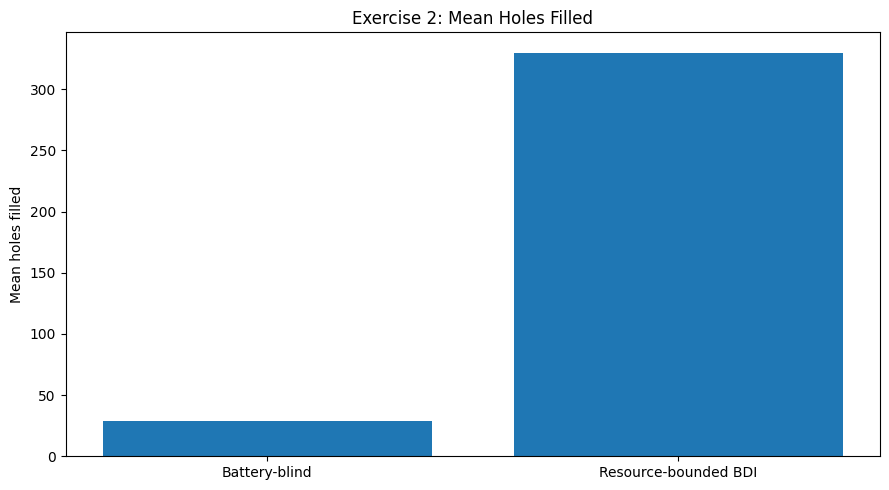

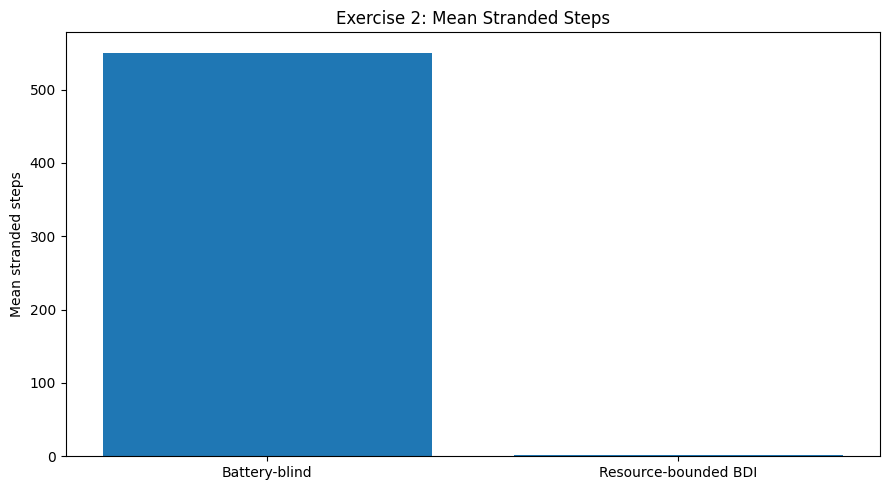

In [19]:
fig,ax=plt.subplots(figsize=(9,5)); ax.bar(resource_summary.agent,resource_summary.mean_filled); ax.set_title("Exercise 2: Mean Holes Filled"); ax.set_ylabel("Mean holes filled"); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); ax.bar(resource_summary.agent,resource_summary.mean_stranded); ax.set_title("Exercise 2: Mean Stranded Steps"); ax.set_ylabel("Mean stranded steps"); plt.tight_layout(); plt.show()

# 13. Exercise 2 Interpretation

The resource constraint belongs in the **filter**, because the filter determines which desires are admissible intentions. The planner should generate the path for the selected intention rather than silently changing the goal.

The resource-aware agent therefore commits only to holes for which the trip plus return to the charger fits the current battery, and chooses recharge otherwise.

# 14. Observations

1. Beliefs are revised from current percepts, allowing the agent to detect environmental changes.
2. Desires are alternatives; the selected desire becomes the intention.
3. Intentions persist under single-minded commitment while achievable.
4. Drop events expose loss of achievement or feasibility.
5. Switch events expose reconsideration and re-planning.
6. Charging deliberation one time step makes the γ comparison fair because the world changes while the agent thinks.
7. Faster worlds make stale intentions more costly, generally favouring shorter reconsideration intervals.
8. Resource feasibility is a deliberation/filter issue, not a planning issue.

# 15. Complexity Discussion

The planner uses BFS over a fixed 15×15 grid. Option generation sorts currently visible holes by distance. A scheduled reconsideration repeats belief revision, option generation, filtering and planning.

The key cost in this experiment is not only CPU time: **deliberation consumes agent time while the world advances**. That creates the central BDI commitment trade-off.

# 16. Final Conclusion

The complete BDI deliberation cycle has been implemented for the dynamic Tileworld. The experiment demonstrates the trade-off between commitment stability and adaptability:

- cautious agents reconsider frequently but pay deliberation cost;
- bold agents avoid repeated deliberation but risk stale intentions;
- intermediate commitment can balance the two.

The resource-bounded extension demonstrates that battery feasibility belongs in the filter because it determines whether a hole is a valid intention. The planner then produces the means–ends path for that selected intention.

Numerical results are specific to the documented stochastic configuration because the supplied PDF leaves several environment parameters unspecified.